In [1]:
from IPython.display import display, Markdown

display(Markdown("""
# Lung Cancer Classification Using SVM

**Project:** Machine Learning Classification

**Algorithm:** Support Vector Machine (SVM)

**Dataset:** Lung Cancer Dataset
"""))


# Lung Cancer Classification Using SVM

**Project:** Machine Learning Classification

**Algorithm:** Support Vector Machine (SVM)

**Dataset:** Lung Cancer Dataset


# Part 1 — Data Loading and Exploratory Data Analysis (EDA)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (3000, 16)


In [4]:
df.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,LUNG_CANCER
0,M,65,1,1,1,2,2,1,2,2,2,2,2,2,1,NO
1,F,55,1,2,2,1,1,2,2,2,1,1,1,2,2,NO
2,F,78,2,2,1,1,1,2,1,2,1,1,2,1,1,YES
3,M,60,2,1,1,1,2,1,2,1,1,2,1,2,2,YES
4,F,80,1,1,2,1,1,2,1,2,1,1,1,1,2,NO


In [5]:
# Identify the target column
target = "LUNG_CANCER"

# Identify the feature columns
features = [col for col in df.columns if col != target]

print("Features:")
for feature in features:
    print("-", feature)

print("\nTarget:")
print(target)

print("\nNumber of Features:", len(features))

Features:
- GENDER
- AGE
- SMOKING
- YELLOW_FINGERS
- ANXIETY
- PEER_PRESSURE
- CHRONIC_DISEASE
- FATIGUE
- ALLERGY
- WHEEZING
- ALCOHOL_CONSUMING
- COUGHING
- SHORTNESS_OF_BREATH
- SWALLOWING_DIFFICULTY
- CHEST_PAIN

Target:
LUNG_CANCER

Number of Features: 15


In [6]:
print("Number of Samples:", df.shape[0])
print("Number of Features:", len(features))
print("Number of Target Variables:", 1)
print("Total Number of Columns:", df.shape[1])

Number of Samples: 3000
Number of Features: 15
Number of Target Variables: 1
Total Number of Columns: 16


In [7]:
import seaborn as sns

sns.set_theme(style="whitegrid")

print("EDA libraries imported successfully!")

EDA libraries imported successfully!


In [8]:
target_col = "LUNG_CANCER"

# Columns stored as numerical data types
numeric_dtype_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

# Columns stored as text or categorical data types
text_categorical_cols = df.select_dtypes(
    exclude=np.number
).columns.tolist()

# Identify binary categorical columns
binary_cols = [
    col for col in numeric_dtype_cols
    if col != target_col and df[col].nunique() == 2
]

# Identify continuous numerical features
numerical_cols = [
    col for col in numeric_dtype_cols
    if col not in binary_cols and col != target_col
]

# Combine categorical features
categorical_cols = [
    col for col in text_categorical_cols
    if col != target_col
] + binary_cols

print("Numerical Features:")
print(numerical_cols)

print("\nCategorical Features:")
print(categorical_cols)

print("\nBinary Features:")
print(binary_cols)

print("\nTarget Variable:")
print(target_col)

Numerical Features:
['AGE']

Categorical Features:
['GENDER', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC_DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL_CONSUMING', 'COUGHING', 'SHORTNESS_OF_BREATH', 'SWALLOWING_DIFFICULTY', 'CHEST_PAIN']

Binary Features:
['SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC_DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL_CONSUMING', 'COUGHING', 'SHORTNESS_OF_BREATH', 'SWALLOWING_DIFFICULTY', 'CHEST_PAIN']

Target Variable:
LUNG_CANCER


In [9]:
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
AGE,3000.0,55.169,14.723746,30.0,42.0,55.0,68.0,80.0


In [10]:
class_counts = df[target_col].value_counts()

print(class_counts)

LUNG_CANCER
YES    1518
NO     1482
Name: count, dtype: int64


In [11]:
class_percentages = (
    df[target_col].value_counts(normalize=True) * 100
)

print(class_percentages.round(2))

LUNG_CANCER
YES    50.6
NO     49.4
Name: proportion, dtype: float64


In [12]:
target_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

display(target_summary)

,Count,Percentage
LUNG_CANCER,,
YES,1518,50.6
NO,1482,49.4


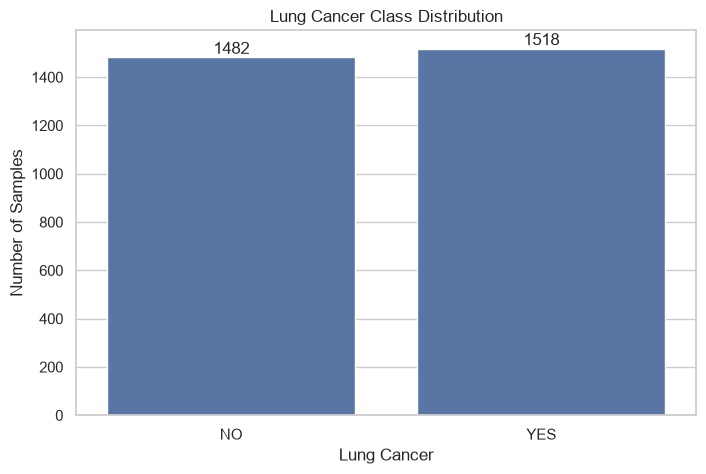

In [13]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x=target_col,
    order=["NO", "YES"]
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Lung Cancer Class Distribution")
plt.xlabel("Lung Cancer")
plt.ylabel("Number of Samples")

plt.show()

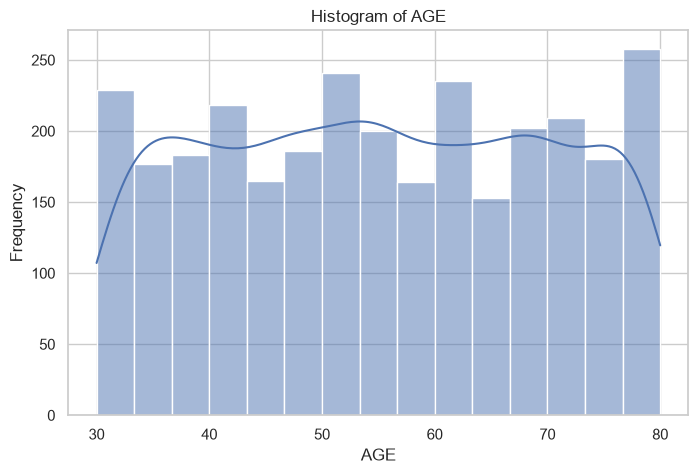

In [14]:
for col in numerical_cols:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=col,
        bins=15,
        kde=True
    )

    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

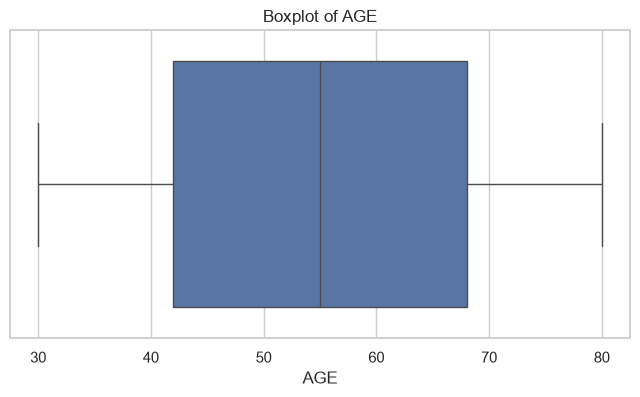

In [15]:
for col in numerical_cols:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.show()

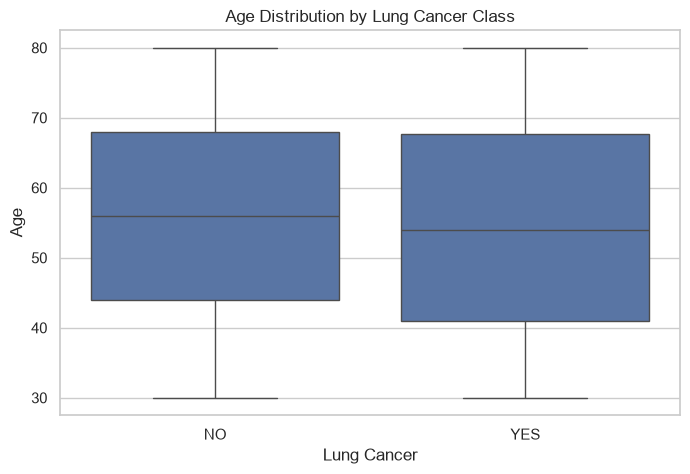

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x=target_col,
    y="AGE",
    order=["NO", "YES"]
)

plt.title("Age Distribution by Lung Cancer Class")
plt.xlabel("Lung Cancer")
plt.ylabel("Age")

plt.show()

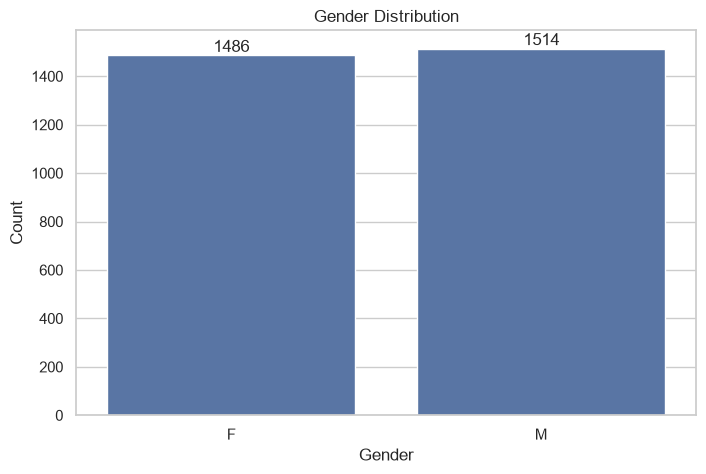

In [17]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="GENDER",
    order=["F", "M"]
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

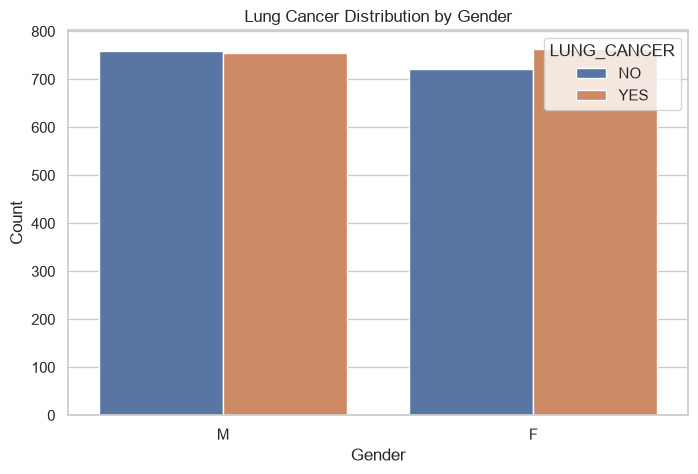

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="GENDER",
    hue=target_col
)

plt.title("Lung Cancer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

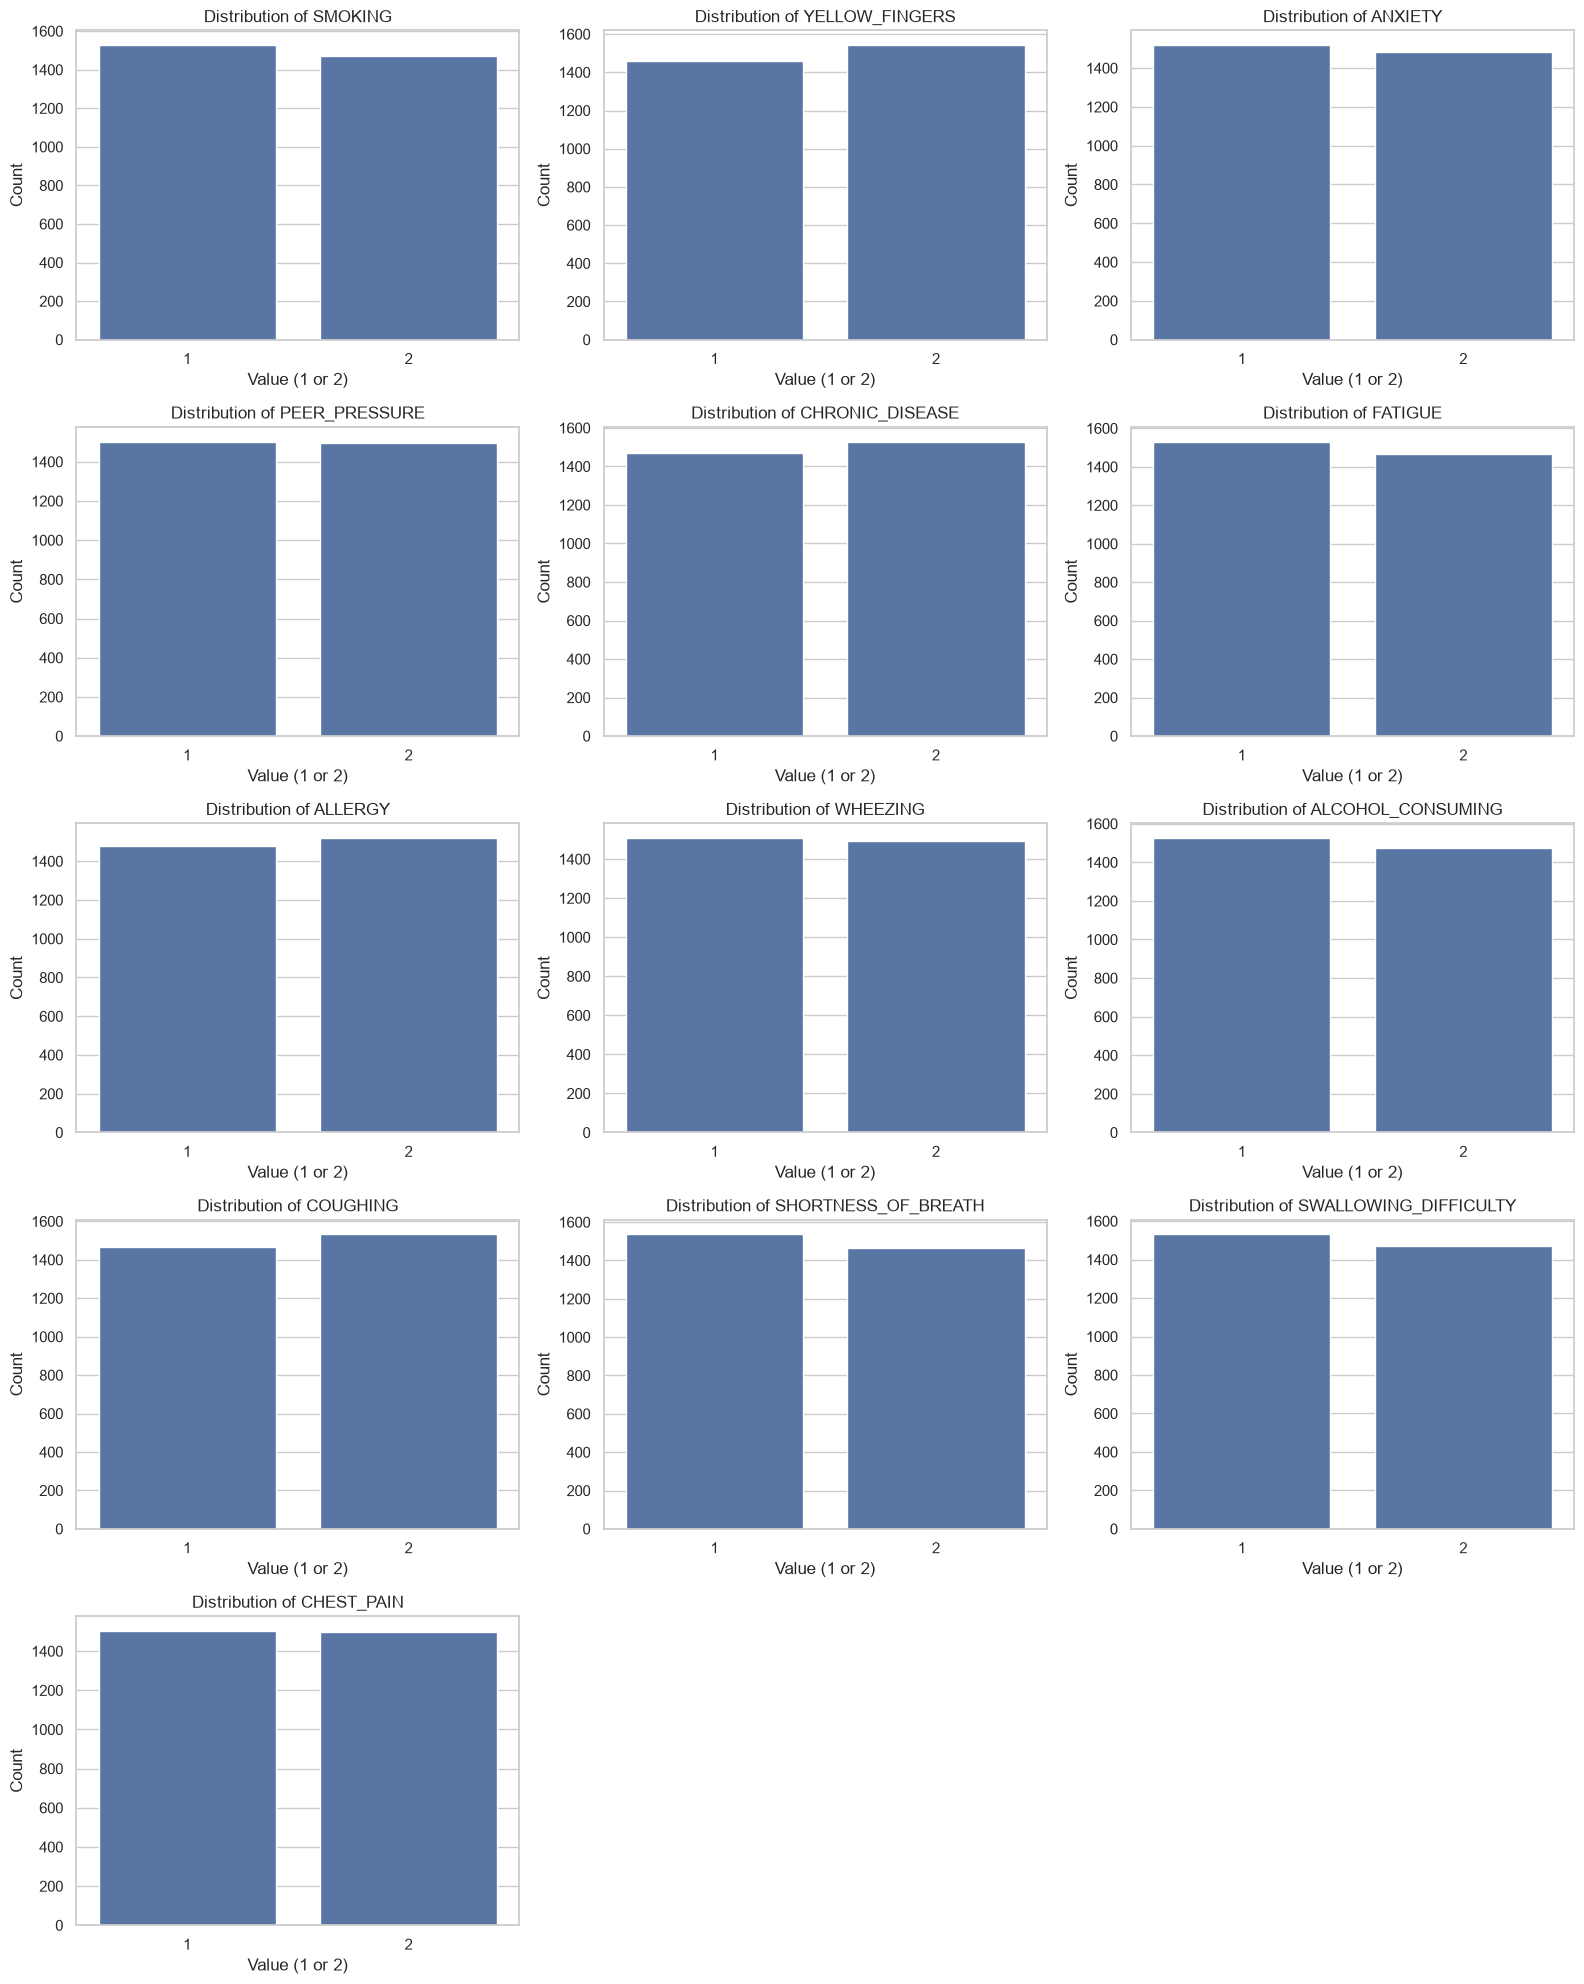

In [19]:
n_cols = 3
n_rows = int(np.ceil(len(binary_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, n_rows * 4)
)

axes = axes.flatten()

for i, col in enumerate(binary_cols):

    ax = sns.countplot(
        data=df,
        x=col,
        order=[1, 2],
        ax=axes[i]
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Value (1 or 2)")
    ax.set_ylabel("Count")

for j in range(len(binary_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

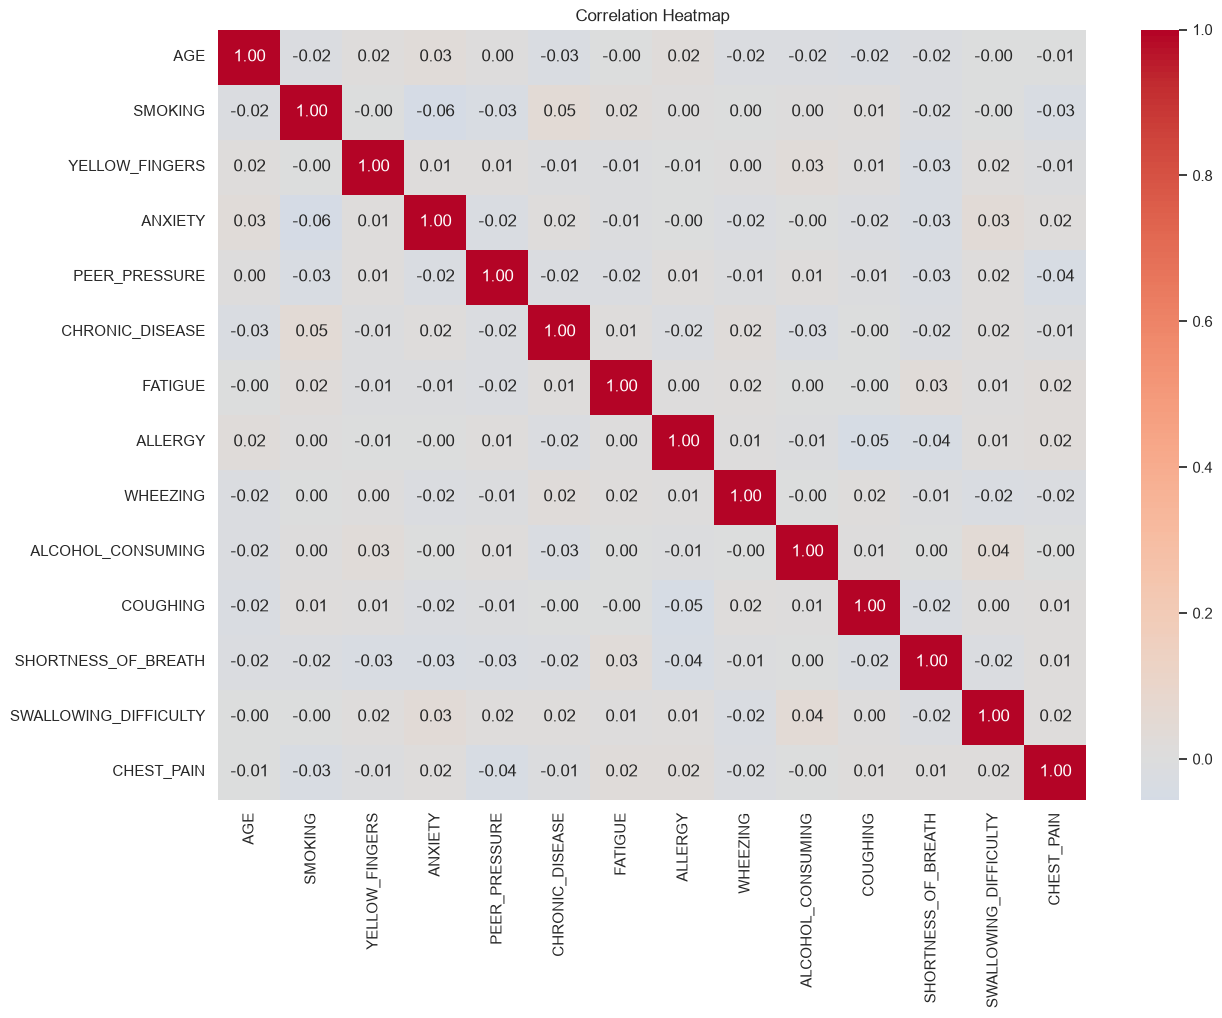

In [20]:
correlation = df[numeric_dtype_cols].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap")

plt.show()

# Part 2 — Data Preprocessing and Train/Test Split

## Student 3 — Data Preprocessing and Train/Test Split (for SVM)

**Shared strategy (agreed with the team):**
1. Remove duplicate rows before splitting.
2. Encode the target: NO -> 0, YES -> 1.
3. Stratified 80/20 split with a fixed seed (random_state = 42).
4. Fit imputers, encoders and the scaler on the TRAINING set only.
5. Transform the test set with the already-fitted preprocessor.
6. Share X_train, X_test, y_train, y_test with Students 4 and 5.

In [21]:
import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "LUNG_CANCER"
OUTPUT_DIR = "split_data"

df = pd.read_csv("dataset.csv")
print("Dataset shape:", df.shape)

Dataset shape: (3000, 16)


## 1. Data quality: missing values and duplicates

In [22]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", int(df.isnull().sum().sum()))

n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"\nDuplicate rows removed: {n_dup}")
print("Shape after cleaning:", df.shape)

Missing values per column:
GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC_DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL_CONSUMING        0
COUGHING                 0
SHORTNESS_OF_BREATH      0
SWALLOWING_DIFFICULTY    0
CHEST_PAIN               0
LUNG_CANCER              0
dtype: int64

Total missing values: 0

Duplicate rows removed: 2
Shape after cleaning: (2998, 16)


## 2. Feature groups and target encoding

In [23]:
NUMERICAL_COLS = ["AGE"]                      # continuous -> impute + scale
TEXT_CAT_COLS = ["GENDER"]                    # text (F/M) -> impute + encode
BINARY_COLS = [                               # coded 1 = NO, 2 = YES -> impute + encode
    "SMOKING", "YELLOW_FINGERS", "ANXIETY", "PEER_PRESSURE",
    "CHRONIC_DISEASE", "FATIGUE", "ALLERGY", "WHEEZING",
    "ALCOHOL_CONSUMING", "COUGHING", "SHORTNESS_OF_BREATH",
    "SWALLOWING_DIFFICULTY", "CHEST_PAIN",
]
FEATURES = NUMERICAL_COLS + TEXT_CAT_COLS + BINARY_COLS

X = df[FEATURES].copy()
y = df[TARGET].str.strip().str.upper().map({"NO": 0, "YES": 1}).astype(int)

print("X shape:", X.shape)
print("Target distribution:\n", y.value_counts().rename({0: "NO (0)", 1: "YES (1)"}))

X shape: (2998, 15)
Target distribution:
 LUNG_CANCER
YES (1)    1517
NO (0)     1481
Name: count, dtype: int64


## 3. Train/test split (stratified, fixed seed)
The split happens BEFORE any fitting, so the test set never influences preprocessing.

In [24]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Train:", X_train_raw.shape, " Test:", X_test_raw.shape)
print(pd.DataFrame({
    "Full (%)":  y.value_counts(normalize=True) * 100,
    "Train (%)": y_train.value_counts(normalize=True) * 100,
    "Test (%)":  y_test.value_counts(normalize=True) * 100,
}).rename(index={0: "NO", 1: "YES"}).round(2))

Train: (2398, 15)  Test: (600, 15)
             Full (%)  Train (%)  Test (%)
LUNG_CANCER                               
YES              50.6      50.58     50.67
NO               49.4      49.42     49.33


## 4. Preprocessing pipeline
- **AGE**: median imputation + StandardScaler (SVM is distance-based, so AGE 30–80
  would otherwise dominate the 0/1 features).
- **GENDER**: most-frequent imputation + encoding (F = 0, M = 1).
- **Binary symptoms**: most-frequent imputation + encoding (1 -> 0, 2 -> 1).

In [25]:
def build_preprocessor():
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="if_binary", handle_unknown="ignore",
                                  sparse_output=False)),
    ])
    return ColumnTransformer(
        [
            ("num", numeric, NUMERICAL_COLS),
            ("gender", categorical, TEXT_CAT_COLS),
            ("binary", categorical, BINARY_COLS),
        ],
        verbose_feature_names_out=False,
    )

preprocessor = build_preprocessor()

## 5. Fit on TRAIN only, then transform train and test

In [26]:
preprocessor.fit(X_train_raw)                       # learns from training data only

feature_names = [n[:-2] if n.endswith("_2") else n  # "SMOKING_2" -> "SMOKING"
                 for n in preprocessor.get_feature_names_out()]

X_train = pd.DataFrame(preprocessor.transform(X_train_raw),
                       columns=feature_names, index=X_train_raw.index)
X_test = pd.DataFrame(preprocessor.transform(X_test_raw),
                      columns=feature_names, index=X_test_raw.index)

scaler = preprocessor.named_transformers_["num"].named_steps["scaler"]
print(f"AGE scaler (fitted on train): mean = {scaler.mean_[0]:.2f}, std = {scaler.scale_[0]:.2f}")
print(f"Scaled AGE  train: mean = {X_train['AGE'].mean():.3f}, std = {X_train['AGE'].std():.3f}")
print(f"Scaled AGE  test : mean = {X_test['AGE'].mean():.3f}, std = {X_test['AGE'].std():.3f}")
X_train.head()

AGE scaler (fitted on train): mean = 54.97, std = 14.69
Scaled AGE  train: mean = 0.000, std = 1.000
Scaled AGE  test : mean = 0.069, std = 1.012


,AGE,GENDER_M,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN
282,-1.155311,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
509,1.568078,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0
1486,-1.563819,0.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
384,1.431909,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0
209,-0.951057,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0


## 6. Final checks

In [27]:
assert X_train.isnull().sum().sum() == 0 and X_test.isnull().sum().sum() == 0
assert list(X_train.columns) == list(X_test.columns)
assert set(X_train_raw.index).isdisjoint(X_test_raw.index)
assert set(np.unique(X_train.drop(columns="AGE"))) <= {0.0, 1.0}
print("All checks passed: no missing values, same columns, no shared rows, binary features are 0/1.")
print("X_train:", X_train.shape, "| X_test:", X_test.shape,
      "| y_train:", y_train.shape, "| y_test:", y_test.shape)

All checks passed: no missing values, same columns, no shared rows, binary features are 0/1.
X_train: (2398, 15) | X_test: (600, 15) | y_train: (2398,) | y_test: (600,)


## 7. Save

In [28]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
X_train.to_csv(f"{OUTPUT_DIR}/X_train.csv", index=False)
X_test.to_csv(f"{OUTPUT_DIR}/X_test.csv", index=False)
y_train.to_frame(TARGET).to_csv(f"{OUTPUT_DIR}/y_train.csv", index=False)
y_test.to_frame(TARGET).to_csv(f"{OUTPUT_DIR}/y_test.csv", index=False)
X_train_raw.to_csv(f"{OUTPUT_DIR}/X_train_raw.csv", index=False)   # for GridSearchCV pipelines
X_test_raw.to_csv(f"{OUTPUT_DIR}/X_test_raw.csv", index=False)
joblib.dump(preprocessor, f"{OUTPUT_DIR}/preprocessor.joblib")

print("Saved:", sorted(os.listdir(OUTPUT_DIR)))

Saved: ['Lung_Cancer.ipynb', 'X_test.csv', 'X_test_raw.csv', 'X_train.csv', 'X_train_raw.csv', 'preprocessor.joblib', 'y_test.csv', 'y_train.csv']


# Part 3 — Student 4: SVM Implementation

## 3.1 Importing SVM Libraries

In [29]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
import pandas as pd

### 3.2 Loading Prepared Data

In [30]:

# Load training and testing data
X_train = pd.read_csv("split_data/X_train.csv")
X_test = pd.read_csv("split_data/X_test.csv")

y_train = pd.read_csv("split_data/y_train.csv").squeeze("columns")
y_test = pd.read_csv("split_data/y_test.csv").squeeze("columns")

# Display dataset shapes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training features: (2398, 15)
Testing features: (600, 15)
Training labels: (2398,)
Testing labels: (600,)


### 3.3 Linear SVM Kernel

In [31]:
# Create Linear SVM model
linear_svm = SVC(
    kernel='linear',
    C=1.0
)

# Train the model
linear_svm.fit(X_train, y_train)

print("Linear SVM model trained successfully.")

Linear SVM model trained successfully.


### 3.4 RBF SVM Kernel

In [32]:
# Create RBF SVM model
rbf_svm = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale'
)

# Train the model
rbf_svm.fit(X_train, y_train)

print("RBF SVM model trained successfully.")

RBF SVM model trained successfully.


### 3.5 Hyperparameter Tuning

In [33]:

# Define parameter grids

linear_params = {
    'C': [0.1, 1, 10, 100]
}

rbf_params = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.1, 1]
}

# Tune Linear SVM
linear_grid = GridSearchCV(
    SVC(kernel='linear'),
    linear_params,
    cv=5,
    scoring='accuracy'
)

linear_grid.fit(X_train, y_train)

# Tune RBF SVM
rbf_grid = GridSearchCV(
    SVC(kernel='rbf'),
    rbf_params,
    cv=5,
    scoring='accuracy'
)

rbf_grid.fit(X_train, y_train)

# Display best parameters
print("Best Linear SVM Parameters:", linear_grid.best_params_)
print("Best RBF SVM Parameters:", rbf_grid.best_params_)


Best Linear SVM Parameters: {'C': 100}
Best RBF SVM Parameters: {'C': 1, 'gamma': 0.1}


### 3.6 Final Models and Predictions

In [34]:

# Select the best models
best_linear_svm = linear_grid.best_estimator_
best_rbf_svm = rbf_grid.best_estimator_

# Generate predictions
y_pred_linear = best_linear_svm.predict(X_test)
y_pred_rbf = best_rbf_svm.predict(X_test)

print("Linear SVM predictions generated:", len(y_pred_linear))
print("RBF SVM predictions generated:", len(y_pred_rbf))


Linear SVM predictions generated: 600
RBF SVM predictions generated: 600


### 3.7 Saving SVM Predictions

In [35]:

# Create a DataFrame containing actual and predicted values
predictions = pd.DataFrame({
    "Actual": y_test,
    "Linear_SVM_Prediction": y_pred_linear,
    "RBF_SVM_Prediction": y_pred_rbf
})

# Save predictions to CSV file
predictions.to_csv("SVM_predictions.csv", index=False)

print("SVM predictions saved successfully.")
print(predictions.head())


SVM predictions saved successfully.
   Actual  Linear_SVM_Prediction  RBF_SVM_Prediction
0       0                      1                   1
1       1                      1                   0
2       1                      1                   1
3       0                      1                   1
4       1                      1                   1


# Student 5 — FLAML AutoML Implementation


## 1. Install FLAML

Install FLAML with its AutoML dependencies. FLAML tests different models and configurations and selects the best one according to the metric we specify.

In [36]:
%pip install "flaml[automl]" 

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

- `AutoML`: the main class used to perform automated model search and training.
- `time`: measures the training duration.
- `os` and `json`: create an output folder and save the results summary.
- `pandas`: organizes the results into tables.
- `sklearn.metrics`: calculates the model's performance on the test set.

In [37]:
import os
import json
import time
import pandas as pd

from flaml import AutoML
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

## 3. Check the shared data


In [38]:
required_variables = ["X_train", "X_test", "y_train", "y_test"]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        "Run Student 3 preprocessing cells first. Missing: "
        + ", ".join(missing_variables)
    )

if list(X_train.columns) != list(X_test.columns):
    raise ValueError("X_train and X_test must have the same columns.")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)
print("Target labels:", sorted(pd.Series(y_train).unique()))

Training features: (2398, 15)
Testing features: (600, 15)
Training target: (2398,)
Testing target: (600,)
Target labels: [np.int64(0), np.int64(1)]


## 4. Configure FLAML

The settings define the automated search:
- `task="classification"` because this is a classification problem.
- `metric="f1"` makes FLAML select the model using the F1-score.
- `time_budget=60` gives the search a maximum budget of 60 seconds.
- `eval_method="holdout"` makes FLAML create an internal validation split from the training data. The test set is not used for model selection.
- `seed=42` helps make the experiment reproducible.

In [39]:
flaml_settings = {
    "task": "classification",
    "metric": "f1",
    "time_budget": 60,
    "eval_method": "holdout",
    "split_ratio": 0.20,
    "seed": 42,
    "verbose": 1
}

automl = AutoML()

## 5. Train the AutoML model

Train FLAML using only `X_train` and `y_train`. Do not provide `X_test` or `y_test` during training. This prevents test-set leakage.

In [40]:
start_time = time.time()

automl.fit(
    X_train=X_train,
    y_train=y_train,
    **flaml_settings
)

training_time = time.time() - start_time

print("Training completed.")
print(f"Training time: {training_time:.2f} seconds")

Training completed.
Training time: 60.18 seconds


## 6. Display the best model and configuration

After the search, FLAML provides:
- `best_estimator`: the type of model selected.
- `best_config`: the best hyperparameter configuration found.
- `best_loss`: the best loss on the internal validation data. FLAML represents the F1-based objective as a loss during optimization.

In [41]:
print("Best estimator:", automl.best_estimator)
print("Best configuration:", automl.best_config)
print("Best validation loss:", automl.best_loss)
print(f"Total training time: {training_time:.2f} seconds")

Best estimator: xgb_limitdepth
Best configuration: {'n_estimators': 24, 'max_depth': 6, 'min_child_weight': np.float64(3.553185150284507), 'learning_rate': np.float64(0.009680925420384862), 'subsample': np.float64(0.8392321560768398), 'colsample_bylevel': np.float64(0.9729014252740672), 'colsample_bytree': np.float64(0.9304022295909337), 'reg_alpha': np.float64(0.023847394868221572), 'reg_lambda': np.float64(111.95524539853601)}
Best validation loss: 0.3239831697054698
Total training time: 60.18 seconds


## 7. Predict on the test set

Use `X_test` to generate predictions. The test set is used here for evaluation, not for selecting or tuning the model.

In [42]:
y_pred_flaml = automl.predict(X_test)

print("First predictions:", y_pred_flaml[:10])

First predictions: [1 1 1 1 1 1 1 1 1 0]


## 8. Evaluate the model

Calculate Accuracy, Precision, Recall, and F1-score. We use `pos_label=1` because the positive class is YES, encoded as `1`.

- Accuracy: the proportion of all predictions that are correct.
- Precision: among the cases predicted as YES, the proportion that are actually YES.
- Recall: among all actual YES cases, the proportion detected by the model.
- F1-score: the harmonic balance between Precision and Recall.

In [43]:
flaml_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_flaml),
    "Precision": precision_score(y_test, y_pred_flaml, pos_label=1, zero_division=0),
    "Recall": recall_score(y_test, y_pred_flaml, pos_label=1, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_flaml, pos_label=1, zero_division=0)
}

flaml_metrics_df = pd.DataFrame(
    list(flaml_metrics.items()),
    columns=["Metric", "FLAML Test Score"]
)

display(flaml_metrics_df)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_flaml, zero_division=0))

,Metric,FLAML Test Score
0,Accuracy,0.515000
1,Precision,0.511265
2,Recall,0.970395
3,F1-score,0.669694



Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.05      0.09       296
           1       0.51      0.97      0.67       304

    accuracy                           0.52       600
   macro avg       0.56      0.51      0.38       600
weighted avg       0.56      0.52      0.38       600



## 9. Visualize FLAML test metrics

This chart displays the test metrics for FLAML only

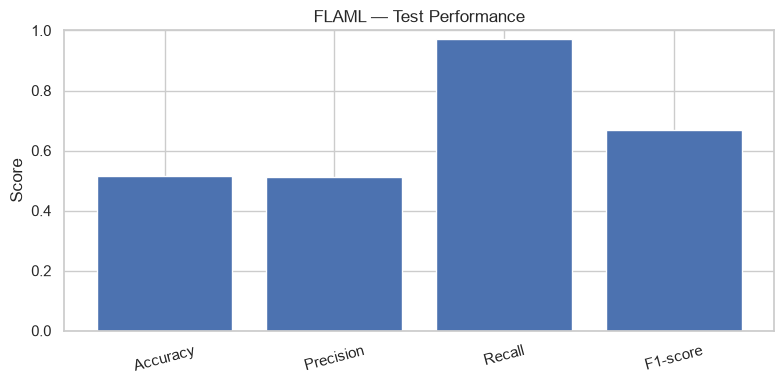

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.bar(flaml_metrics_df["Metric"], flaml_metrics_df["FLAML Test Score"])
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("FLAML — Test Performance")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 10. Save results

Save FLAML's predictions, metrics, and summary in `split_data` (or in `OUTPUT_DIR` if it was already defined).

In [45]:
OUTPUT_DIR = globals().get("OUTPUT_DIR", "split_data")
os.makedirs(OUTPUT_DIR, exist_ok=True)

predictions_path = os.path.join(OUTPUT_DIR, "flaml_test_predictions.csv")
metrics_path = os.path.join(OUTPUT_DIR, "flaml_test_metrics.csv")
summary_path = os.path.join(OUTPUT_DIR, "flaml_summary.json")

pd.DataFrame({
    "y_true": pd.Series(y_test).reset_index(drop=True),
    "y_pred_flaml": pd.Series(y_pred_flaml).reset_index(drop=True)
}).to_csv(predictions_path, index=False)

flaml_metrics_df.to_csv(metrics_path, index=False)

flaml_summary = {
    "best_estimator": str(automl.best_estimator),
    "best_config": automl.best_config,
    "best_validation_loss": float(automl.best_loss),
    "training_time_seconds": float(training_time),
    "test_metrics": {key: float(value) for key, value in flaml_metrics.items()}
}

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(flaml_summary, file, indent=4, ensure_ascii=False)

print("Saved files:")
print(predictions_path)
print(metrics_path)
print(summary_path)

Saved files:
split_data\flaml_test_predictions.csv
split_data\flaml_test_metrics.csv
split_data\flaml_summary.json


## 11. conclusion and handover

In this section, FLAML AutoML was used to search for and select a classification model automatically. The selected model was trained using only the training set and evaluated on the test set using Accuracy, Precision, Recall, and F1-score.

- `flaml_test_predictions.csv`
- `flaml_test_metrics.csv`
- `flaml_summary.json`
- 